In [1]:
# importing all necessary imports
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split 

In [2]:
#importing the train dataset 
df = pd.read_csv('StressLevelDataset.csv')

In [3]:
df.sample(10)

,anxiety_level,self_esteem,mental_health_history,depression,headache,blood_pressure,sleep_quality,breathing_problem,noise_level,living_conditions,...,basic_needs,academic_performance,study_load,teacher_student_relationship,future_career_concerns,social_support,peer_pressure,extracurricular_activities,bullying,stress_level
1051,3,29,0,1,1,2,4,2,1,4,...,4,5,1,5,1,3,2,1,1,0
777,16,10,1,18,5,3,1,3,3,1,...,2,2,4,1,5,1,5,4,4,2
998,5,29,0,8,1,2,5,2,1,4,...,4,4,2,4,1,3,1,1,1,0
968,4,29,0,6,1,2,5,1,2,3,...,4,5,2,5,1,3,2,2,1,0
296,4,9,1,4,2,3,5,3,1,3,...,0,4,4,2,5,1,0,4,5,0
1027,12,22,1,12,3,1,3,4,2,3,...,3,2,3,2,3,2,2,2,3,1
970,13,25,1,11,3,1,2,4,3,2,...,2,2,3,3,2,2,3,2,2,1
80,4,26,0,5,1,2,5,2,2,4,...,4,4,1,5,1,3,2,2,1,0
687,21,8,1,27,4,3,1,5,5,1,...,2,1,5,2,5,1,4,4,5,2
165,15,4,1,26,3,3,1,5,5,2,...,2,1,4,1,5,1,4,5,4,2


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1100 entries, 0 to 1099
Data columns (total 21 columns):
 #   Column                        Non-Null Count  Dtype
---  ------                        --------------  -----
 0   anxiety_level                 1100 non-null   int64
 1   self_esteem                   1100 non-null   int64
 2   mental_health_history         1100 non-null   int64
 3   depression                    1100 non-null   int64
 4   headache                      1100 non-null   int64
 5   blood_pressure                1100 non-null   int64
 6   sleep_quality                 1100 non-null   int64
 7   breathing_problem             1100 non-null   int64
 8   noise_level                   1100 non-null   int64
 9   living_conditions             1100 non-null   int64
 10  safety                        1100 non-null   int64
 11  basic_needs                   1100 non-null   int64
 12  academic_performance          1100 non-null   int64
 13  study_load                    110

In [5]:
#the data set is balanced
df['stress_level'].value_counts()

stress_level
0    373
2    369
1    358
Name: count, dtype: int64

In [6]:
# train/test split
x = df.drop(columns = ['stress_level'])
y = df['stress_level']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=42) 

              precision    recall  f1-score   support

           0       0.90      0.88      0.89       113
           1       0.85      0.91      0.88       107
           2       0.92      0.88      0.90       110

    accuracy                           0.89       330
   macro avg       0.89      0.89      0.89       330
weighted avg       0.89      0.89      0.89       330



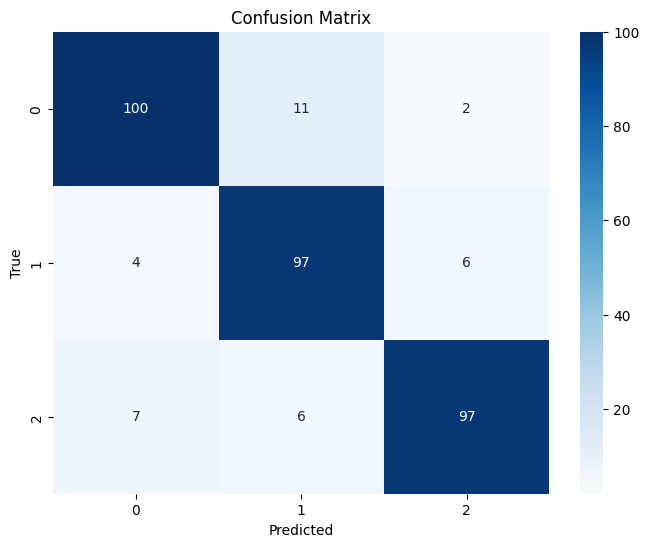

In [8]:
#training a Decision Tree Classifier
dtc = DecisionTreeClassifier(random_state=42).fit(x_train,y_train)
y_pred0 = dtc.predict(x_test)

print(classification_report (y_test, y_pred0))

cm = confusion_matrix(y_test, y_pred0)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

              precision    recall  f1-score   support

           0       0.86      0.89      0.88       113
           1       0.92      0.92      0.92       107
           2       0.92      0.88      0.90       110

    accuracy                           0.90       330
   macro avg       0.90      0.90      0.90       330
weighted avg       0.90      0.90      0.90       330



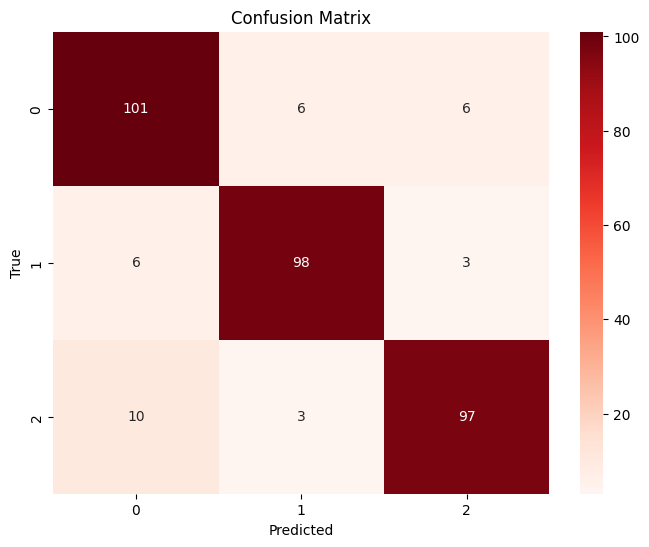

In [9]:
#training a Random Forest Classifier
rfc = RandomForestClassifier(random_state=42).fit(x_train,y_train)

y_pred3 = rfc.predict(x_test)

print(classification_report(y_test, y_pred3))

cm = confusion_matrix(y_test, y_pred3)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

              precision    recall  f1-score   support

           0       0.95      0.88      0.92       113
           1       0.90      0.93      0.92       107
           2       0.89      0.93      0.91       110

    accuracy                           0.92       330
   macro avg       0.92      0.92      0.92       330
weighted avg       0.92      0.92      0.92       330



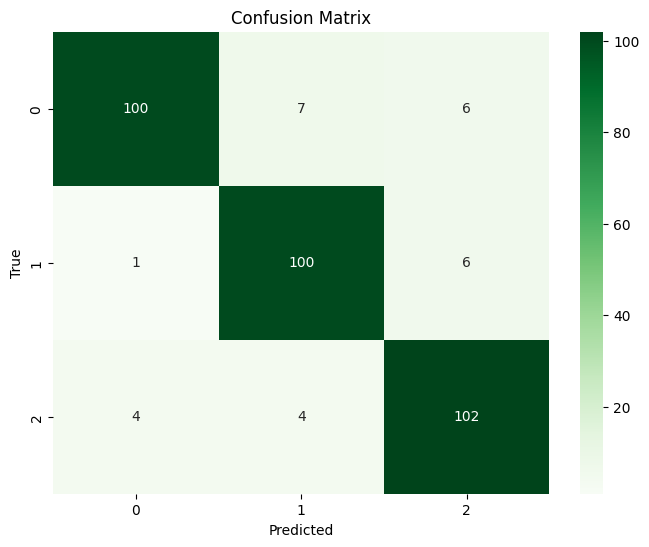

In [10]:
#training a support vector machine
svm = SVC(random_state=42).fit(x_train,y_train)

y_pred1 = svm.predict(x_test)

print(classification_report(y_test, y_pred1))

cm = confusion_matrix(y_test, y_pred1)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

              precision    recall  f1-score   support

           0       0.92      0.86      0.89       113
           1       0.87      0.91      0.89       107
           2       0.87      0.90      0.88       110

    accuracy                           0.89       330
   macro avg       0.89      0.89      0.89       330
weighted avg       0.89      0.89      0.89       330



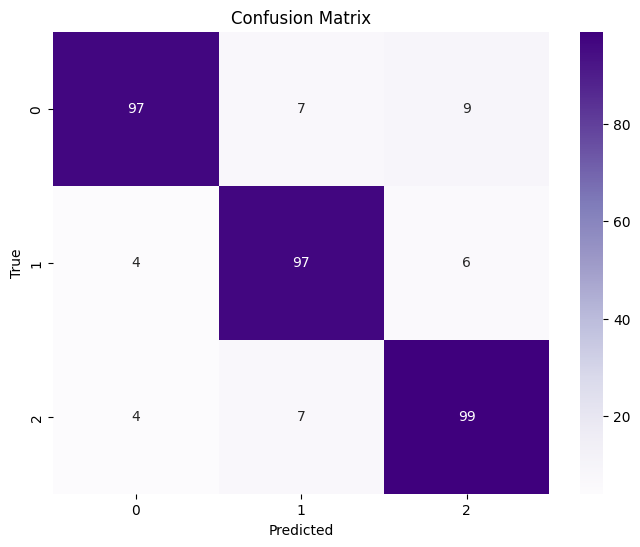

In [11]:
#training a KNN
knn = KNeighborsClassifier(n_neighbors=3).fit(x_train,y_train)

y_pred2 = knn.predict(x_test)

print(classification_report(y_test, y_pred2))

cm = confusion_matrix(y_test, y_pred2)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

In [12]:
#training a LinearRegression
lrg = LinearRegression().fit(x_train,y_train)

print('Accuracy : ',lrg.score(x_test,y_test))

Accuracy :  0.7892052608112265
